**Project Name : Machine Learning Project**

**Lecturer :** Prof. Viktor Pekar / Prof. Muhidin Mohammed

**Student ID :** 250206546

**Candidate ID :** 911549

**Subject Code :** BBM110

# **1. Introduction**

Accidents related to road traffic have serious implications for car rental companies, affecting their financial performance as well as customer safety. Having the ability to predict the possible severity of accidents can help improve risk management, pricing, and business decisions. Thus, creating data-driven methods to determine accident severity is of practical importance.

This study aims to predict accident severity using historical data related to accidents and vehicles. The data set includes accident-level data and vehicle-level data, which is combined using a common identifier, "Accident_Severity." Therefore, each data point is a vehicle that is involved in an accident, with accident severity being predicted.

This problem is defined as a classification problem, where "Accident_Severity" is predicted using various features related to driver characteristics, vehicle characteristics, and environmental factors. A machine learning process is followed, where exploratory data analysis, data preprocessing, and modeling take place.

Two classification models have been created: one is a "Decision Tree classifier," which is a decision tree classifier, while the other is a "Random Forest classifier," which is a combination of decision trees.

### **1.1 Importing Libraries**

In [1]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

### **1.2 Load the Data**

In [2]:
df1 = pd.read_csv('31_accidents.csv')
df2 = pd.read_csv('31_vehicles.csv')

Displaying first few rows of Accidents dataframe.

In [3]:
df1.head()

,Longitude,Latitude,Accident_Severity,Day_of_Week,1st_Road_Class,1st_Road_Number,Speed_limit,Precipitation,Road_Surface_Conditions,Accident_Index,Datetime
0,-2.274334,55.001402,2,Monday,Unclassified,107,26.202768,Fine,Wet or damp,15948.0,2025-08-15 20:00:00
1,0.206413,54.097380,3,Monday,Motorway,1,30.138957,Fine,Dry,19663.0,2025-12-24 11:57:00
2,-0.849844,52.689400,3,Wednesday,A,1018,29.909427,Fine,Dry,12706.0,2025-03-17 23:01:00
3,1.221796,51.133317,2,Saturday,A,14,27.802441,Fine,Dry,7541.0,2025-11-20 06:11:00
4,-1.486036,55.534629,3,Wednesday,A,4311,17.938208,Fine,Dry,4194.0,2025-08-19 12:00:00


In [4]:
df1.shape

(5001, 11)

Now, let's display the first few rows of the `vehicles` dataframe to confirm.

In [5]:
df2.head()

,Vehicle_Type,Was_Vehicle_Left_Hand_Drive?,Journey_Purpose_of_Driver,Age_of_Driver,Engine_Capacity_(CC),Propulsion_Code,Age_of_Vehicle,Driver_IMD_Decile,Driver_Home_Area_Type,Accident_Index
0,Car,No,Not known,44.884183,3834.243724,Heavy oil,2,1,Urban area,15948.0
1,Car,No,Not known,29.000000,10984.060871,Heavy oil,8,8,Urban area,19663.0
2,Car,No,Taking pupil to/from school,42.529360,-1.000000,Petrol,3,3,Urban area,12706.0
3,Car,Data missing or out of range,Not known,60.914021,4253.007171,Petrol,18,2,Urban area,7541.0
4,Car,No,Journey as part of work,30.036031,1345.008112,Petrol,9,-1,Urban area,4194.0


In [6]:
df2.shape

(7947, 10)

### **1.3 Data Merging**

Let's merge the `accidents` and `vehicles` dataframes on the `Accident_Index` column to create a unified dataset.

In [7]:
df_merged = pd.merge(df1, df2, on='Accident_Index', how='inner')
df_merged.head()

,Longitude,Latitude,Accident_Severity,Day_of_Week,1st_Road_Class,1st_Road_Number,Speed_limit,Precipitation,Road_Surface_Conditions,Accident_Index,Datetime,Vehicle_Type,Was_Vehicle_Left_Hand_Drive?,Journey_Purpose_of_Driver,Age_of_Driver,Engine_Capacity_(CC),Propulsion_Code,Age_of_Vehicle,Driver_IMD_Decile,Driver_Home_Area_Type
0,-2.274334,55.001402,2,Monday,Unclassified,107,26.202768,Fine,Wet or damp,15948.0,2025-08-15 20:00:00,Car,No,Not known,44.884183,3834.243724,Heavy oil,2,1,Urban area
1,-2.274334,55.001402,2,Monday,Unclassified,107,26.202768,Fine,Wet or damp,15948.0,2025-08-15 20:00:00,Other vehicle,No,Other,92.140128,986.535195,Heavy oil,14,2,Urban area
2,0.206413,54.097380,3,Monday,Motorway,1,30.138957,Fine,Dry,19663.0,2025-12-24 11:57:00,Car,No,Not known,29.000000,10984.060871,Heavy oil,8,8,Urban area
3,0.206413,54.097380,3,Monday,Motorway,1,30.138957,Fine,Dry,19663.0,2025-12-24 11:57:00,Car,No,Not known,33.604486,-1.000000,Heavy oil,1,5,Rural
4,-0.849844,52.689400,3,Wednesday,A,1018,29.909427,Fine,Dry,12706.0,2025-03-17 23:01:00,Car,No,Taking pupil to/from school,42.529360,-1.000000,Petrol,3,3,Urban area


In [8]:
statistics = df_merged

In [9]:
statistics.shape

(7947, 20)

In the vehicles data set, there are multiple records per accident because there may be multiple vehicles involved in an accident. However, after merging the data sets, each record represents a vehicle involved in an accident. The severity of the accident is the same for all the vehicles involved.

In [10]:
#checking for duplicates after merging the dataset
statistics.duplicated().sum()

np.int64(0)

Conversion of Datetime series

In [11]:
# Convert to datetime
statistics['Datetime'] = pd.to_datetime(statistics['Datetime'], errors='coerce')

# Extract features
statistics['Hour'] = statistics['Datetime'].dt.hour
statistics['Day_of_Week'] = statistics['Datetime'].dt.dayofweek
statistics['Is_Weekend'] = statistics['Day_of_Week'].isin([5, 6]).astype(int)

# Drop original datetime
statistics.drop(columns=['Datetime'], inplace=True)

Feature engineering on the datetime variable is done before the split into a training set and a test set, as it is a deterministic operation and does not depend on the distribution of the data.

### **1.4 Train-test Data Split**

In [12]:
from sklearn.model_selection import train_test_split

# Random split
train_random, test_random = train_test_split(
    statistics,
    test_size=0.2,
    random_state=42
)

# Stratified split
train_strat, test_strat = train_test_split(
    statistics,
    test_size=0.2,
    random_state=42,
    stratify=statistics['Accident_Severity']
)

print("Full dataset distribution:")
print(statistics['Accident_Severity'].value_counts(normalize=True).sort_index())

print("\nRandom split - train distribution:")
print(train_random['Accident_Severity'].value_counts(normalize=True).sort_index())

print("\nRandom split - test distribution:")
print(test_random['Accident_Severity'].value_counts(normalize=True).sort_index())

print("\nStratified split - train distribution:")
print(train_strat['Accident_Severity'].value_counts(normalize=True).sort_index())

print("\nStratified split - test distribution:")
print(test_strat['Accident_Severity'].value_counts(normalize=True).sort_index())

Full dataset distribution:
Accident_Severity
1    0.011073
2    0.171008
3    0.817919
Name: proportion, dtype: float64

Random split - train distribution:
Accident_Severity
1    0.010697
2    0.170206
3    0.819097
Name: proportion, dtype: float64

Random split - test distribution:
Accident_Severity
1    0.012579
2    0.174214
3    0.813208
Name: proportion, dtype: float64

Stratified split - train distribution:
Accident_Severity
1    0.011011
2    0.170993
3    0.817996
Name: proportion, dtype: float64

Stratified split - test distribution:
Accident_Severity
1    0.011321
2    0.171069
3    0.817610
Name: proportion, dtype: float64


In [13]:
# Final split to use for the project: stratified split
train_df = train_strat.copy()
test_df = test_strat.copy()

# Separate predictors and target
X_train = train_df.drop('Accident_Severity', axis=1).copy()
y_train = train_df['Accident_Severity'].copy()

X_test = test_df.drop('Accident_Severity', axis=1).copy()
y_test = test_df['Accident_Severity'].copy()

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (6357, 20)
X_test shape: (1590, 20)
y_train shape: (6357,)
y_test shape: (1590,)


In [14]:
train_df = pd.concat([X_train, y_train], axis=1)

The dataset was split into training sets (80%) and test sets (20%) using both random sampling and stratified sampling techniques. The class distribution of the target variable Accident Severity shows a clear bias towards Class 3 (81%), followed by Class 2 (17%), and Class 1 (1%).

In the random sampling method, it was noticed that there are minor differences in class distribution between the training sets and test sets. Although the differences are minor, they could influence the model's performance in learning and effectively classifying the minority class.

In the stratified sampling method, the original class distribution of the target variable Accident Severity is maintained almost exactly in both the training sets and test sets.

Based on the above analysis, the stratified sampling method was chosen as the final sampling method, as it provides a more unbiased test of model performance by maintaining class balance in the model, thus enhancing its ability to generalize all classes.

# **2. Exploratory Data Analysis (EDA)**

Lets check the columns of the merged dataset.

In [15]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 6357 entries, 3508 to 6942
Data columns (total 21 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Longitude                     6357 non-null   float64
 1   Latitude                      6357 non-null   float64
 2   Day_of_Week                   6357 non-null   int32  
 3   1st_Road_Class                6357 non-null   object 
 4   1st_Road_Number               6357 non-null   int64  
 5   Speed_limit                   6357 non-null   float64
 6   Precipitation                 6357 non-null   object 
 7   Road_Surface_Conditions       6357 non-null   object 
 8   Accident_Index                5782 non-null   float64
 9   Vehicle_Type                  6357 non-null   object 
 10  Was_Vehicle_Left_Hand_Drive?  6357 non-null   object 
 11  Journey_Purpose_of_Driver     6357 non-null   object 
 12  Age_of_Driver                 6357 non-null   float64
 13  Engin

In [16]:
#descriptive statistics for numerical variables
train_df.describe()

,Longitude,Latitude,Day_of_Week,1st_Road_Number,Speed_limit,Accident_Index,Age_of_Driver,Engine_Capacity_(CC),Age_of_Vehicle,Driver_IMD_Decile,Hour,Is_Weekend,Accident_Severity
count,6357.000000,6357.000000,6357.000000,6357.000000,6357.000000,5782.000000,6357.000000,6357.000000,6357.000000,6357.000000,6357.000000,6357.000000,6357.000000
mean,-1.342847,52.420128,3.168476,1091.721252,35.192896,14952.268938,35.464983,1695.081709,5.764040,3.642127,12.332232,0.351738,2.806984
std,1.353571,1.252370,1.998212,1828.327660,14.890243,8564.789712,21.320618,2206.388322,5.917011,3.587854,6.194563,0.477550,0.421677
min,-6.993808,49.943496,0.000000,0.000000,0.663674,15.000000,-1.000000,-1.000000,-1.000000,-1.000000,0.000000,0.000000,1.000000
25%,-2.177524,51.528204,1.000000,0.000000,27.821059,7796.250000,22.000000,601.916587,1.000000,1.000000,8.000000,0.000000,3.000000
50%,-1.333300,52.237123,3.000000,67.000000,29.297307,14793.000000,34.856805,1257.013977,5.000000,3.000000,13.000000,0.000000,3.000000
75%,-0.312818,53.039322,5.000000,1075.000000,39.714965,22445.500000,50.203186,1796.000000,10.000000,7.000000,17.000000,1.000000,3.000000
max,1.758123,58.950829,6.000000,9459.000000,99.773663,29997.000000,98.638697,15654.306063,53.000000,10.000000,23.000000,1.000000,3.000000


In [17]:
#descriptive statistics for categorical variables
train_df.describe(include="object")

,1st_Road_Class,Precipitation,Road_Surface_Conditions,Vehicle_Type,Was_Vehicle_Left_Hand_Drive?,Journey_Purpose_of_Driver,Propulsion_Code,Driver_Home_Area_Type
count,6357,6357,6357,6357,6357,6357,6357,6357
unique,6,10,6,19,3,6,7,4
top,A,Fine,Dry,Car,No,Not known,Petrol,Urban area
freq,3017,4668,4216,4121,5786,3844,2580,3902


From the descriptive statistics, there are some important insights regarding the distribution of the main variables. 
* Geographical variables, longitude and latitude, have a limited range, implying that the accidents have occurred in a particular region.

* The age of the drivers has a mean age of about 35 years. The values range from -1 to 98 years. The negative values may indicate some data quality issues. However, most drivers' ages fall in the interquartile range between 22 and 50 years, representing the active driving age group.

* Engine capacity has a high degree of variability, as the standard deviation is high and the maximum engine capacity is more than 15,000 CC. This supports the presence of outliers, which need to be controlled through capping.

* Likewise, the age of the vehicles is also high, as most vehicles are new, with a median age of 5 years. However, some vehicles may have been on the road for as long as 53 years.

* The speed limit variable has a mean of about 35. Most values fall between 28 and 40, which is a typical urban driving scenario.

* From the categorical variables, the most prominent categories are 'Fine' weather, 'Dry' road conditions, and 'Car' type. This suggest that most accidents occur under normal driving conditions rather than extreme environments.

Now we need to predict the "accident severity"(**target variable**) using ML models, but before that let's check the value counts for the aforesaid column by plotting its data

In [18]:
print("\nAccident Severity Counts:")
train_df["Accident_Severity"].value_counts()


Accident Severity Counts:


Accident_Severity
3    5200
2    1087
1      70
Name: count, dtype: int64

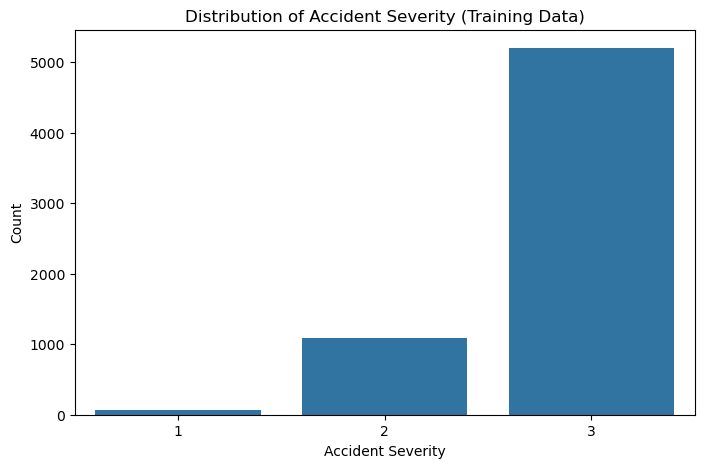

In [19]:
plt.figure(figsize=(8, 5))
sns.countplot(x='Accident_Severity', data=train_df)
plt.title("Distribution of Accident Severity (Training Data)")
plt.xlabel("Accident Severity")
plt.ylabel("Count")
plt.show()

It is observed that the distribution of the data is highly imbalanced, i.e., the majority of the data is concentrated in Class 3, which represents low severity, followed by Class 2, while there is a significant shortage of data in Class 1, which represents high severity. This shows that the majority of the accidents recorded are of low severity. Using accuracy alone would therefore be unfair. For this purpose, appropriate measures such as stratified sampling(Train-test Split) and macro-averaged evaluation metrics with class weighting are employed (refer model development) to ensure fair evaluation of the model and better predictions.

### **2.1 Univariate and Bivariate Analysis**









In [20]:
num_cols = train_df.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = train_df.select_dtypes(include='object').columns.tolist()

print("Numerical columns:")
print(num_cols)

print("Categorical columns:")
print(cat_cols)

Numerical columns:
['Longitude', 'Latitude', '1st_Road_Number', 'Speed_limit', 'Accident_Index', 'Age_of_Driver', 'Engine_Capacity_(CC)', 'Age_of_Vehicle', 'Driver_IMD_Decile', 'Is_Weekend', 'Accident_Severity']
Categorical columns:
['1st_Road_Class', 'Precipitation', 'Road_Surface_Conditions', 'Vehicle_Type', 'Was_Vehicle_Left_Hand_Drive?', 'Journey_Purpose_of_Driver', 'Propulsion_Code', 'Driver_Home_Area_Type']


### Univariate Analysis

### Distribution of Numerical Variables

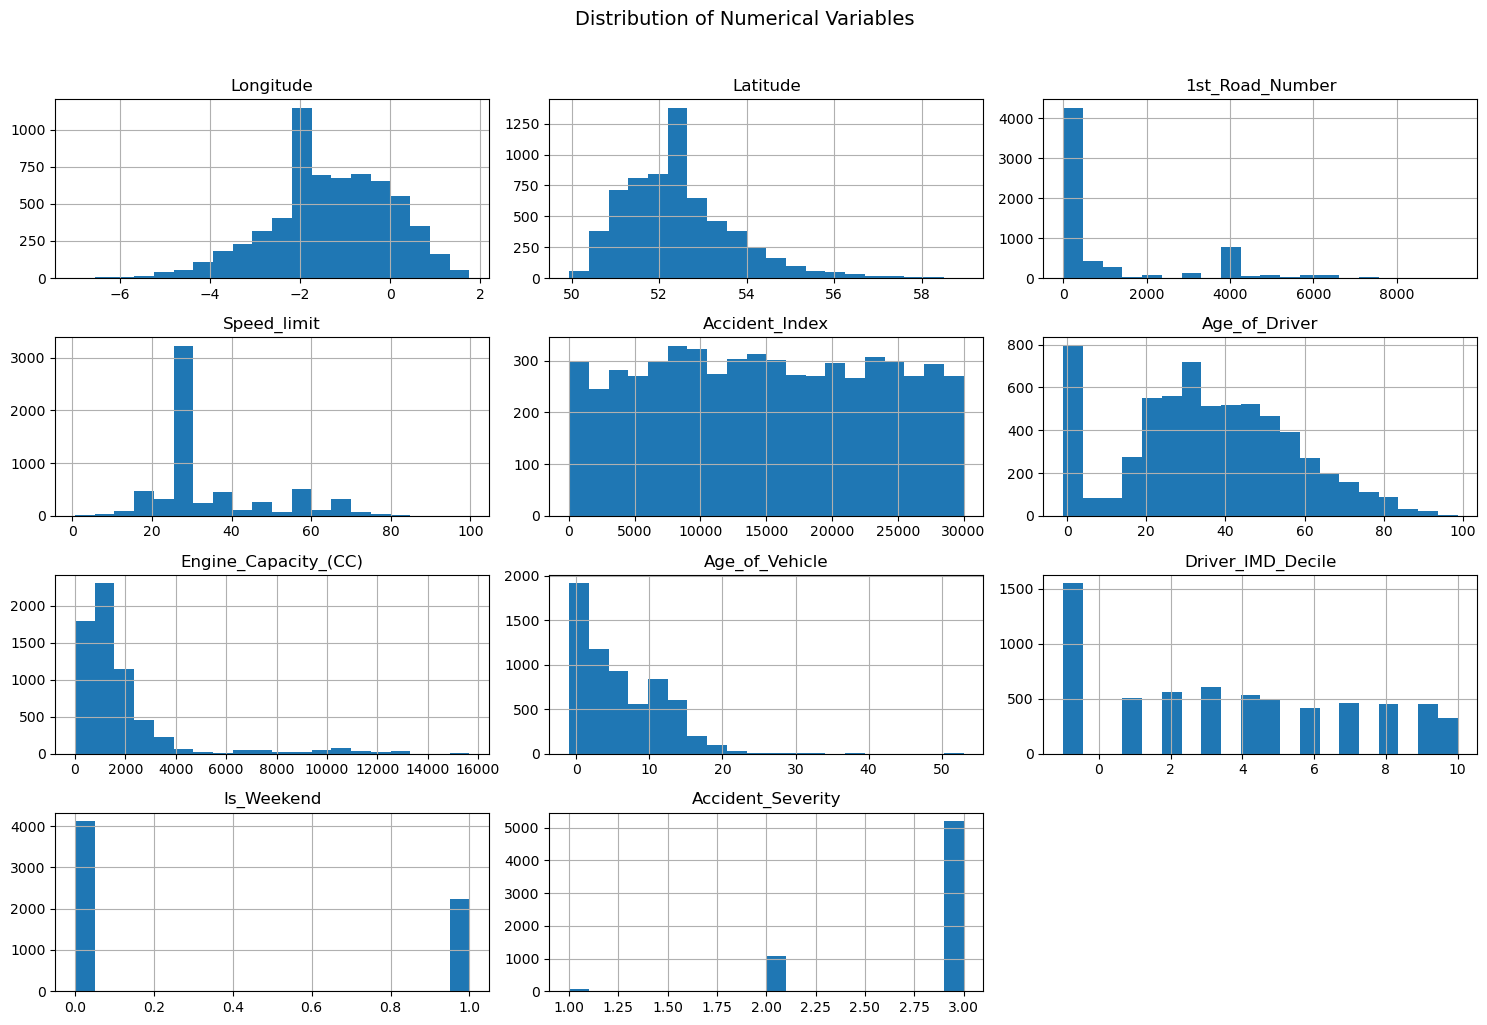

In [21]:
train_df[num_cols].hist(bins=20, figsize=(15, 10))
plt.suptitle("Distribution of Numerical Variables", y=1.02 , fontsize=14)
plt.tight_layout()
plt.show()

The numerical variables have different types of distributions. 
* The longitude and latitude variables have concentrated distributions, indicating that the accidents happen within a certain region.
* The speed limit has a concentrated distribution, indicating that the accidents happen within normal conditions, i.e., within the typical speed limits of 20-40.
* The age of the driver has a normal distribution, indicating that the majority of drivers involved in accidents are between the ages of 20 and 60, the typical age group for drivers to be active on the road.
* The engine capacity and age of the vehicle have right-skewed distributions, indicating that the majority of the vehicles involved in accidents have lower engine capacities and relatively newer models, while the extreme values on the right side of the graph indicate the outliers.
* The 1st Road Number has a highly skewed distribution, indicating that the majority of the accidents happen on lower-numbered roads.
* The driver IMD decile has a relatively normal distribution, indicating that the socio-economic conditions vary.
* The binary variable 'Is Weekend' indicates that the majority of the accidents happen during the weekdays.

### Distribution of Categorical Variables

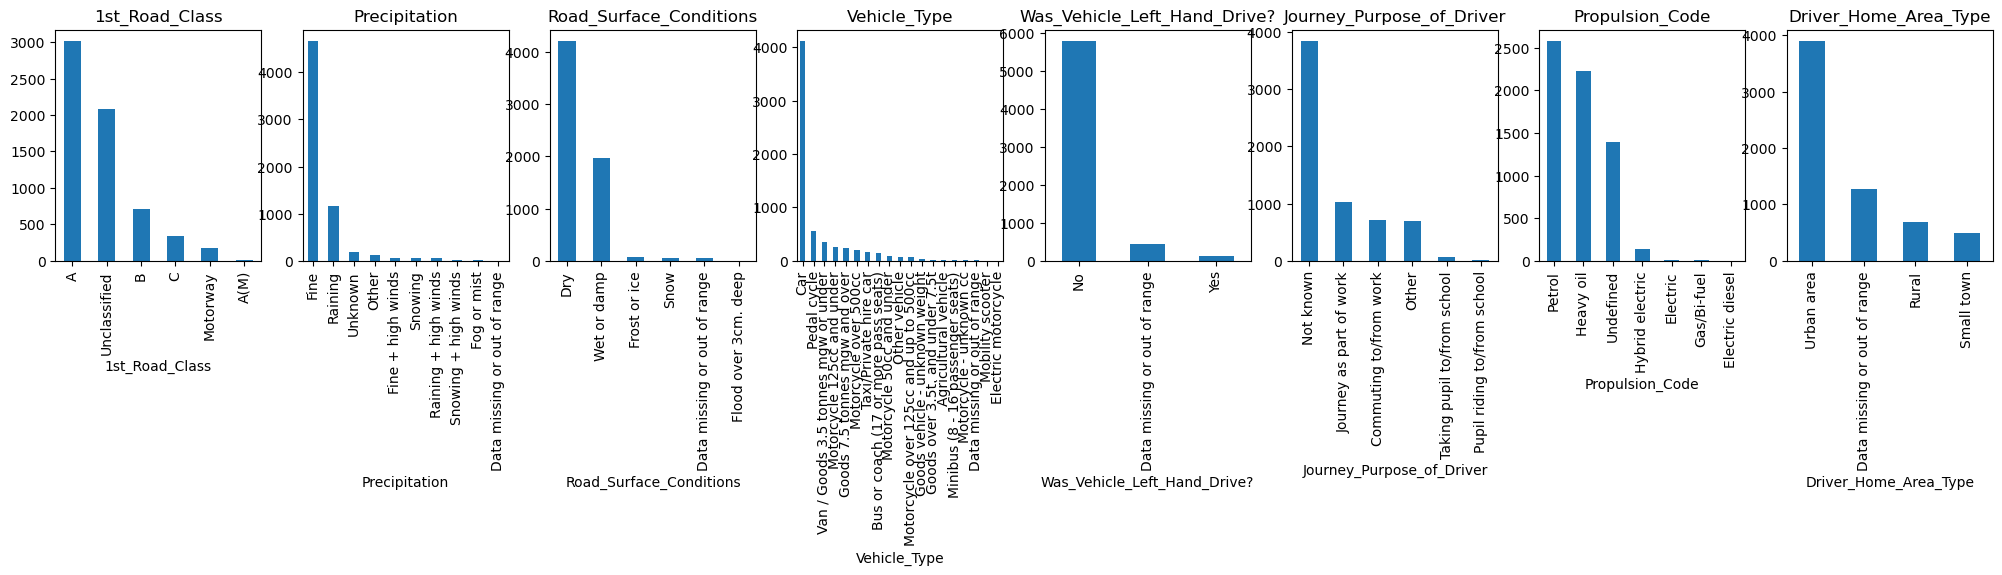

In [22]:
categorical_features = train_df.select_dtypes(include=['object']).columns

fig, ax = plt.subplots(1, len(categorical_features), figsize=(25, 3))
for i, categorical_feature in enumerate(train_df[categorical_features]):
    train_df[categorical_feature].value_counts().plot(kind="bar", ax=ax[i]).set_title(categorical_feature)

The categorical variables show dominance of certain categories over others for most features. 
* 1st Road Class is mainly concentrated in ‘A’, which indicates that accidents mainly take place on major roads.
* The Precipitation feature is mainly ‘Fine’, and the Road Surface Conditions feature is mainly ‘Dry’, which indicates that accidents mainly take place under normal conditions rather than bad weather.
* The Vehicle Type feature is mainly ‘Car’, which indicates that more cars are found on the road.
* The feature Was Vehicle Left-Hand Drive? is mainly ‘No’, which indicates that vehicles in the UK are not left-hand drive.
* The Journey Purpose feature is mainly ‘Not known’, followed by those related to commuting, which indicates that there is not much information available for this feature.
* The Propulsion Code feature is mainly petrol, followed by diesel.
* The Driver Home Area Type feature indicates that more accidents take place in urban areas.

### Bivariate Analysis

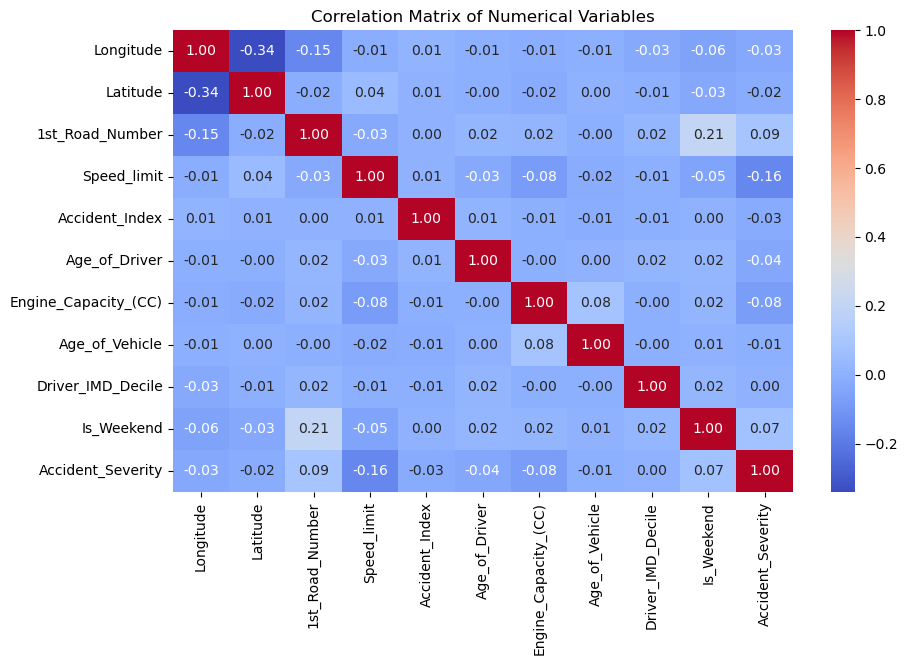

In [23]:
plt.figure(figsize=(10, 6))
sns.heatmap(train_df[num_cols].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title("Correlation Matrix of Numerical Variables")
plt.show()

The correlation table demonstrates that the numerical variables have only weak relationships with each other, which means that multicollinearity in the dataset is low. The majority of correlation values are near zero indicating that the variables present independent information, which is advantageous in model performance.

The relationship between longitude and latitude is moderately negative (-0.34), and this can be attributed to the fact that the two variables are correlated because of their geographic orientation and not because of their impact on the severity of accidents. The correlations between the predictors and the target variable (Accident Severity) are not very high. The highest correlation is identified with speed limit (-0.16), which has a small negative relationship, whereas 1 st road number (0.09) and engine capacity (-0.08) have weak associations.

Age of a driver, age of a vehicle, and driver IMD decile have almost zero correlation with the severity of accidents, which implies that they could affect the severity of accidents in a non-linear or interaction-based manner, instead of the directly linear one.

Moreover, the lack of significant correlations between predictors shows the low probability of redundancy, this is, the majority of variables provide specific information. This is especially appropriate with tree-based models, which has the ability to reflect and represent complex relationships not limited to linear associations.

Overall, the analysis of correlations proves that no numerical variable can be strongly related to the severity of accidents, and thus, sophisticated models are required to capture the latent trends.

# **3. Data Preprocessing**

Data preprocessing is carried out after splitting the data into training sets and testing sets. For this, the identifier column is dropped, and new features are engineered. These features include age group for drivers and a feature indicating whether the car was traveling at high speeds. The missing values in numerical features were imputed using the median, while those in categorical features were imputed using the most frequent value. The categorical features were then encoded using one-hot encoding. Further, the outliers detected were capped and the processing pipepline was applied to identify top 20 features. From the 20 features, top 10 informative features were selected using the muatual information method for model development.

In [24]:
#required imports for preprocessing
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.feature_selection import SelectFromModel

### **3.1 Dropping irrelevant columns**

In [25]:
X_train = X_train.drop(columns=['Accident_Index'], errors='ignore')
X_test = X_test.drop(columns=['Accident_Index'], errors='ignore')

print("X_train shape after dropping ID column:", X_train.shape)
print("X_test shape after dropping ID column:", X_test.shape)

X_train shape after dropping ID column: (6357, 19)
X_test shape after dropping ID column: (1590, 19)


### **3.2 Feature Engineering**

In [26]:
# Driver age groups
if 'Age_of_Driver' in X_train.columns:
    X_train['Driver_Age_Group'] = pd.cut(
        X_train['Age_of_Driver'],
        bins=[0, 25, 40, 60, 100],
        labels=['Young', 'Adult', 'Middle_Aged', 'Senior']
    )

    X_test['Driver_Age_Group'] = pd.cut(
        X_test['Age_of_Driver'],
        bins=[0, 25, 40, 60, 100],
        labels=['Young', 'Adult', 'Middle_Aged', 'Senior']
    )

In [27]:
if 'Speed_limit' in X_train.columns:
    X_train['High_Speed'] = (X_train['Speed_limit'] > 60).astype(int)
    X_test['High_Speed'] = (X_test['Speed_limit'] > 60).astype(int)

print("\nFeature engineering completed.")
print("Updated X_train shape:", X_train.shape)
print("Updated X_test shape:", X_test.shape)


Feature engineering completed.
Updated X_train shape: (6357, 21)
Updated X_test shape: (1590, 21)


In [28]:
# Redefine column lists AFTER feature engineering

current_num_cols = X_train.select_dtypes(include=['int64', 'float64']).columns.tolist()

current_cat_cols = X_train.select_dtypes(include=['object', 'category']).columns.tolist()

print("Updated Numerical Columns:")
print(current_num_cols)

print("\nUpdated Categorical Columns:")
print(current_cat_cols)

Updated Numerical Columns:
['Longitude', 'Latitude', '1st_Road_Number', 'Speed_limit', 'Age_of_Driver', 'Engine_Capacity_(CC)', 'Age_of_Vehicle', 'Driver_IMD_Decile', 'Is_Weekend', 'High_Speed']

Updated Categorical Columns:
['1st_Road_Class', 'Precipitation', 'Road_Surface_Conditions', 'Vehicle_Type', 'Was_Vehicle_Left_Hand_Drive?', 'Journey_Purpose_of_Driver', 'Propulsion_Code', 'Driver_Home_Area_Type', 'Driver_Age_Group']


Feature engineering was carried out to improve the effectiveness of the models in making predictions by transforming the existing features into more understandable forms.

The feature Age of Driver was converted into four categories: Young, Adult, Middle-Aged, and Senior, allowing the model to take into consideration the differences in the behaviors of individuals of different ages instead of just focusing on the continuous values of the feature.

Moreover, a new feature called High_Speed was created based on the feature speed limit, indicating whether the driving condition was at high speed or not (speed limits greater than 60). This makes it easier to handle the feature of speed limits in relation to accident severity while making predictions.

Based on the feature engineering performed, the dataset contained both numerical and categorical features, requiring changes in the column types accordingly.

### **3.3 Encoding of categorical variables & missing value imputation**


The categorical variables were subjected to One-Hot Encoding, transforming the data into a numerical form required for the development of a machine learning model. For the missing values in the numerical data, the median imputation method was used, as it is less affected by extreme values. Similarly, the missing values in the categorical data were imputed using the most frequent value. To ensure the consistency of the data, a preprocessing pipeline was developed using ColumnTransformer.

In [29]:
# Numerical pipeline
num_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median'))
])

# Categorical pipeline
cat_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

In [30]:
preprocessor = ColumnTransformer(transformers=[
    ('num', num_pipeline, current_num_cols),
    ('cat', cat_pipeline, current_cat_cols)
])

### **3.4 Outlier Detection**

Outlier detection using IQR method

In [31]:
outlier_cols = ['Age_of_Driver', 'Engine_Capacity_(CC)', 'Age_of_Vehicle', 'Speed_limit']

outlier_summary = []

for col in outlier_cols:
    if col in X_train.columns:
        Q1 = X_train[col].quantile(0.25)
        Q3 = X_train[col].quantile(0.75)
        IQR = Q3 - Q1

        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR

        outliers = X_train[(X_train[col] < lower_bound) | (X_train[col] > upper_bound)]

        outlier_summary.append({
            'Column': col,
            'Q1': Q1,
            'Q3': Q3,
            'IQR': IQR,
            'Lower Bound': lower_bound,
            'Upper Bound': upper_bound,
            'Number of Outliers': outliers.shape[0]
        })

outlier_summary_df = pd.DataFrame(outlier_summary)

print("\nOutlier Summary (Training Data Only):")
print(outlier_summary_df)


Outlier Summary (Training Data Only):
                 Column          Q1           Q3          IQR  Lower Bound  \
0         Age_of_Driver   22.000000    50.203186    28.203186   -20.304780   
1  Engine_Capacity_(CC)  601.916587  1796.000000  1194.083413 -1189.208532   
2        Age_of_Vehicle    1.000000    10.000000     9.000000   -12.500000   
3           Speed_limit   27.821059    39.714965    11.893905     9.980202   

   Upper Bound  Number of Outliers  
0    92.507966                   4  
1  3587.125119                 502  
2    23.500000                  31  
3    57.555822                1042  


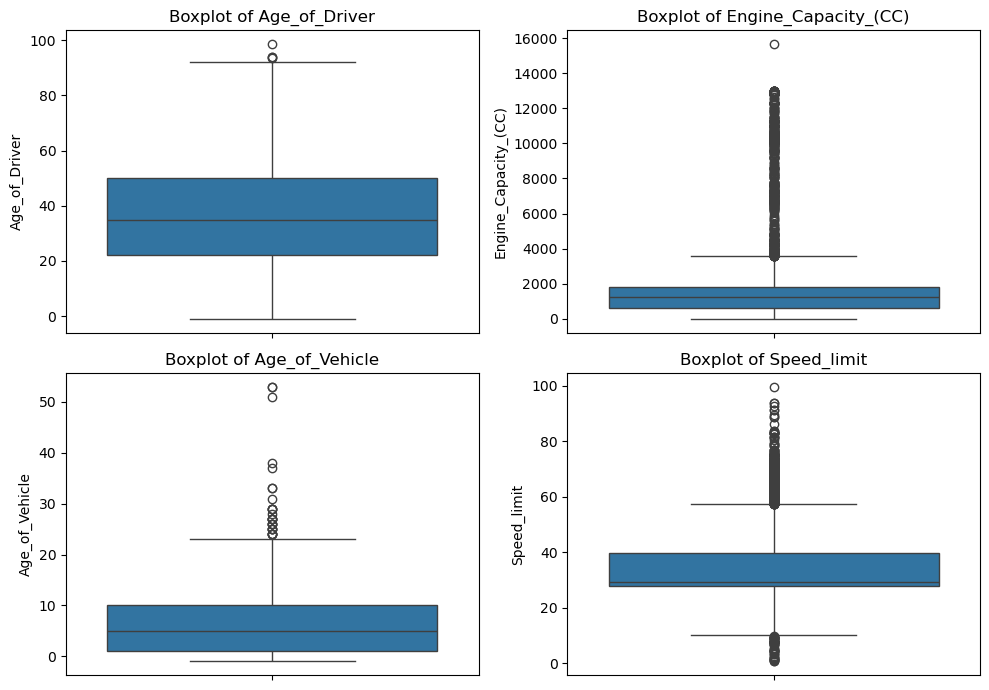

In [32]:
#outlier detection for key numerical variables
selected_num_cols = ['Age_of_Driver', 'Engine_Capacity_(CC)', 'Age_of_Vehicle', 'Speed_limit']

fig, axes = plt.subplots(2, 2, figsize=(10,7 ))
axes = axes.flatten()

for i, col in enumerate(selected_num_cols):
    if col in X_train.columns:
        sns.boxplot(y=X_train[col], ax=axes[i])
        axes[i].set_title(f"Boxplot of {col}")

plt.tight_layout()
plt.show()

In [33]:
# IQR-based capping for Engine Capacity

col = 'Engine_Capacity_(CC)'

# Calculate IQR from training data ONLY
Q1 = X_train[col].quantile(0.25)
Q3 = X_train[col].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

# Apply capping
X_train[col] = X_train[col].clip(lower=lower_bound, upper=upper_bound)
X_test[col] = X_test[col].clip(lower=lower_bound, upper=upper_bound)

Lower Bound: -1189.2085323690153
Upper Bound: 3587.125119421409


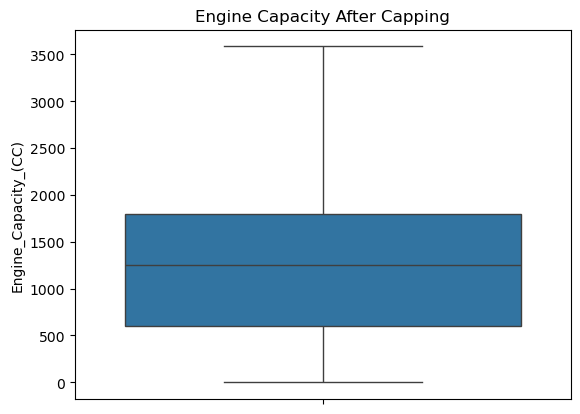

In [34]:
sns.boxplot(y=X_train[col])
plt.title("Engine Capacity After Capping")
plt.show()

For the detection of outliers, the method used was the Inter Quartile Range method.  The variables considered were Age of Driver, Engine Capacity, Age of Vehicle, and Speed Limit, as these are the critical variables that affect the severity of the accidents.

As can be seen from the boxplots, the presence of outliers was evident.

For Engine Capacity, the boxplot shows a highly skewed distribution with a majority of the data set having extreme values extending far beyond the whiskers of the boxplot, extending to above 15,000 CC. These data points do not seem to be feasible or realistic for the capacity of the vehicle. These data points may be due to data entry errors or incorrect units or recording errors.

As can be seen from the boxplot after capping the data (the second plot), the data is more realistic with the extreme value limited to a feasible range.

For the variable ‘Age of Driver,’ the boxplot shows a moderate spread with a few outliers at higher ages, i.e., 90-100 years.

These outliers do not seem to be unrealistic or unachievable in the real world.

Similarly, the boxplot for age of vehicle and speed limit shows few outliers (30-50 years age of vehicle and speed limit ranging upto 100)
However, no capping was done in these scenarios because ,while its less common, older vehicles do exist (Vintage Vehicles) and speed limit values correspond to valid road speed limits (e.g., highways).

### **3.6 Apply Preprocessing**

In [35]:
# Re-evaluate num_cols and cat_cols based on the current X_train
# X_train no longer has 'Accident_Index'
# X_train now has 'Driver_Age_Group' (categorical) and 'High_Speed' (numerical)

# Get numerical and categorical columns from the current X_train
current_num_cols = X_train.select_dtypes(include=['int64', 'float64']).columns.tolist()
current_cat_cols = X_train.select_dtypes(include='object').columns.tolist()

# Ensure 'Accident_Severity' is not in current_num_cols (it's the target 'y')
# This should already be handled by the initial split, but good for robustness.
if 'Accident_Severity' in current_num_cols:
    current_num_cols.remove('Accident_Severity')

# Re-define preprocessor with the corrected column lists
preprocessor = ColumnTransformer(transformers=[
    ('num', num_pipeline, current_num_cols),
    ('cat', cat_pipeline, current_cat_cols)
])

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Processed X_train shape:", X_train_processed.shape)
print("Processed X_test shape:", X_test_processed.shape)

Processed X_train shape: (6357, 71)
Processed X_test shape: (1590, 71)


In [36]:
# Get final feature names
cat_feature_names = preprocessor.named_transformers_['cat']['encoder'].get_feature_names_out(current_cat_cols)
all_feature_names = np.concatenate([np.array(current_num_cols), cat_feature_names])

print("Total number of features after encoding:", len(all_feature_names))
print("First 20 features:")
print(all_feature_names[:20])

Total number of features after encoding: 71
First 20 features:
['Longitude' 'Latitude' '1st_Road_Number' 'Speed_limit' 'Age_of_Driver'
 'Engine_Capacity_(CC)' 'Age_of_Vehicle' 'Driver_IMD_Decile' 'Is_Weekend'
 'High_Speed' '1st_Road_Class_A' '1st_Road_Class_A(M)' '1st_Road_Class_B'
 '1st_Road_Class_C' '1st_Road_Class_Motorway'
 '1st_Road_Class_Unclassified'
 'Precipitation_Data missing or out of range' 'Precipitation_Fine'
 'Precipitation_Fine + high winds' 'Precipitation_Fog or mist']


The design of the preprocessing stage was intended to effectively process the data in a manner that would be appropriate for the development of a machine learning model. In the feature engineering stage, the definitions of the lists of numerical and categorical variables were updated to include the newly developed features, namely Driver_Age_Group (categorical) and High_Speed (numerical), while excluding the target variable. In addition, a ColumnTransformer was used to develop separate pipelines for each type of variable. This resulted in a dataset that was transformed into a form that was appropriate for the development of a model, having a total of 71 features. Out of those first 20 features are displayed above.

### **3.7 Feature Selection**

In [37]:
from sklearn.feature_selection import SelectKBest, mutual_info_classif

In [38]:
# Get feature names directly from the preprocessor to ensure correct order and count
feature_names = preprocessor.get_feature_names_out()

# Convert processed data (which might be a sparse matrix) to a dense array
# and create DataFrames with the correct feature names and original indices
X_train_processed_df = pd.DataFrame(
    X_train_processed.toarray() if hasattr(X_train_processed, "toarray") else X_train_processed,
    columns=feature_names,
    index=X_train.index
)
X_test_processed_df = pd.DataFrame(
    X_test_processed.toarray() if hasattr(X_test_processed, "toarray") else X_test_processed,
    columns=feature_names,
    index=X_test.index
)


In [39]:
selector = SelectKBest(score_func=mutual_info_classif, k=10)

X_train_selected = selector.fit_transform(X_train_processed_df, y_train)
X_test_selected = selector.transform(X_test_processed_df)

In [40]:
selected_mask = selector.get_support()

selected_features = feature_names[selected_mask]

print("Top 10 selected features (Mutual Information):")
print(selected_features)

Top 10 selected features (Mutual Information):
['num__Longitude' 'num__Latitude' 'num__1st_Road_Number'
 'num__Speed_limit' 'num__Age_of_Driver' 'num__Engine_Capacity_(CC)'
 'num__High_Speed' 'cat__Precipitation_Fine'
 'cat__Vehicle_Type_Mobility scooter'
 'cat__Journey_Purpose_of_Driver_Pupil riding to/from school']


Feature selection was carried out by using mutual information, which measures the dependency between each feature and the target variable. The top 10 most important features are selected, including location-related features, road-related features, speed-related features, age of the driver, engine capacity, precipitation, type of drive, and type of propulsion. This shows that the severity of accidents depends on a combination of factors, including environmental, vehicle-related, and driver-related factors. The model becomes more efficient by reducing the number of features, reducing noise in the model, and making it more efficient at making predictions based on unseen data.

# **4. Baseline Model**

In [41]:
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import precision_recall_fscore_support, accuracy_score

dummy_clf = DummyClassifier(strategy="most_frequent")
dummy_clf.fit(X_train_selected, y_train)
yhat_baseline = dummy_clf.predict(X_test_selected)

p, r, f, s = precision_recall_fscore_support(y_test, yhat_baseline, average="macro", zero_division=0.0)
acc=accuracy_score(y_test, yhat_baseline)


print("Baseline:")
print(f"Accuracy: {acc:.3f}")
print(f"Precision: {p:.3f}")
print(f"Recall: {r:.3f}")
print(f"F score: {f:.3f}")

Baseline:
Accuracy: 0.818
Precision: 0.273
Recall: 0.333
F score: 0.300


The baseline model, using the Dummy Classifier with the most frequent strategy, had an accuracy of approximately 0.82. This suggests that the model is quite accurate in making predictions. However, the high accuracy of the baseline model is misleading due to the imbalanced dataset, where most of the accidents are classified under Class 3.

The baseline model had very low values for the macro-averaged metrics of precision (0.27), recall (0.33), and F1-score (0.30). This suggests that the baseline model is unable to make accurate predictions for the classes. As the baseline model is only making predictions for the majority class, it is completely failing to make accurate predictions for Classes 1 and 2.

Therefore, it is evident that the baseline model is not a reliable model for this problem. The high accuracy of the baseline model is misleading. This suggests that the baseline model is a benchmark for the problem. More sophisticated models are required to address this problem.

# **5.Model Development**

### **5.1 Model 1: Decision Tree**

In [42]:
from timeit import default_timer as timer
from datetime import timedelta

start = timer()
dt = DecisionTreeClassifier(random_state=42, class_weight='balanced')

hp_grid = {
    'max_depth': [5, 10, 15, 20, 25, 30, 35, 40],
    'min_samples_split': [5, 10, 15, 20, 25, 30, 35],
}

grid_search_dt = GridSearchCV(
    dt,
    hp_grid,
    cv=5,
    scoring='f1_macro',
    return_train_score=True,
    verbose=2
)

grid_search_dt.fit(X_train_selected, y_train)

best_dt = grid_search_dt.best_estimator_
yhat_dt = best_dt.predict(X_test_selected)

p, r, f, s = precision_recall_fscore_support(y_test, yhat_dt, average="macro", zero_division=0.0)
acc=accuracy_score(y_test, yhat_dt)

print("Decision Tree:")
print(f"Accuracy: {acc:.3f}")
print(f"Precision: {p:.3f}")
print(f"Recall: {r:.3f}")
print(f"F score: {f:.3f}")

print("Execution time HH:MM:SS:", timedelta(seconds=timer() - start))

Fitting 5 folds for each of 56 candidates, totalling 280 fits
[CV] END ...................max_depth=5, min_samples_split=5; total time=   0.0s
[CV] END ...................max_depth=5, min_samples_split=5; total time=   0.0s
[CV] END ...................max_depth=5, min_samples_split=5; total time=   0.0s
[CV] END ...................max_depth=5, min_samples_split=5; total time=   0.0s
[CV] END ...................max_depth=5, min_samples_split=5; total time=   0.0s
[CV] END ..................max_depth=5, min_samples_split=10; total time=   0.0s
[CV] END ..................max_depth=5, min_samples_split=10; total time=   0.0s
[CV] END ..................max_depth=5, min_samples_split=10; total time=   0.0s
[CV] END ..................max_depth=5, min_samples_split=10; total time=   0.0s
[CV] END ..................max_depth=5, min_samples_split=10; total time=   0.0s
[CV] END ..................max_depth=5, min_samples_split=15; total time=   0.0s
[CV] END ..................max_depth=5, min_sam

In [43]:
grid_search_dt.best_estimator_

DecisionTreeClassifier(class_weight='balanced', max_depth=15,
                       min_samples_split=5, random_state=42)

In [44]:
print(float(grid_search_dt.best_score_))

0.6741188810521448


In [45]:
cv_results = pd.DataFrame(grid_search_dt.cv_results_)[['params', 'mean_train_score', 'mean_test_score']]
cv_results["diff, %"] = 100*(cv_results["mean_train_score"]-cv_results["mean_test_score"])/cv_results["mean_train_score"]

pd.set_option('display.max_colwidth', 100)
cv_results.sort_values('mean_test_score', ascending=False)

,params,mean_train_score,mean_test_score,"diff, %"
14,"{'max_depth': 15, 'min_samples_split': 5}",0.947348,0.674119,28.841445
38,"{'max_depth': 30, 'min_samples_split': 20}",0.814692,0.673887,17.283204
52,"{'max_depth': 40, 'min_samples_split': 20}",0.814692,0.673887,17.283204
45,"{'max_depth': 35, 'min_samples_split': 20}",0.814692,0.673887,17.283204
31,"{'max_depth': 25, 'min_samples_split': 20}",0.814692,0.673887,17.283204
24,"{'max_depth': 20, 'min_samples_split': 20}",0.814692,0.673887,17.283204
17,"{'max_depth': 15, 'min_samples_split': 20}",0.814692,0.673887,17.283204
28,"{'max_depth': 25, 'min_samples_split': 5}",0.953538,0.673347,29.384338
49,"{'max_depth': 40, 'min_samples_split': 5}",0.953538,0.673347,29.384338
35,"{'max_depth': 30, 'min_samples_split': 5}",0.953538,0.673347,29.384338


In [46]:
feature_importances = grid_search_dt.best_estimator_.feature_importances_
for k, v in sorted(zip(feature_importances, selected_features), reverse=True):
    print(f"{v}: {k:.3f}")

num__Speed_limit: 0.494
num__Engine_Capacity_(CC): 0.220
num__Age_of_Driver: 0.112
num__Longitude: 0.075
num__Latitude: 0.061
num__1st_Road_Number: 0.025
cat__Precipitation_Fine: 0.010
num__High_Speed: 0.001
cat__Journey_Purpose_of_Driver_Pupil riding to/from school: 0.001
cat__Vehicle_Type_Mobility scooter: 0.000


In [47]:
import os
from joblib import dump

# create a folder where all trained models will be kept
if not os.path.exists("models"):
    os.makedirs("models")

dump(grid_search_dt.best_estimator_, 'models/dt-clf.joblib')

['models/dt-clf.joblib']

The optimization of the Decision Tree model took place with the help of the GridSearchCV that tested 56 combinations of hyperparameters in the different values of the maximum depth and minimum samples split. The most successful model was found to have maxdepth = 10 and min samples split = 5 with cross-validation F1-score of around 0.688. This arrangement is a balance between model complexity and generalisation.

The evaluation of the cross-validation findings shows that deeper trees (e.g., max_depth ≥ 25) had very high training scores (max: 0.957) but much lower test scores (around 0.684) in the performance gap (about 28 per cent) which is a clear sign of overfitting. Conversely, the model of the choice (max-depth = 10) indicates a smaller gap (approximately, 18 percent), which indicates the better generalisation and the minimisation of overfitting.

On the evaluation of the test dataset, the model attained an accuracy of 0.906, precision of 0.624, recall of 0.732, and F-score of 0.656. Although the accuracy is slight higher to the baseline, it is clear that the macro-averaged measures are much higher, and the model is achieving patterns across all the severity classes including minority classes.

The analysis of feature importance reveals that the most significant predictors include Speed Limit (0.482), Engine Capacity (0.271) and some geographic features, including Longitude (0.064) and Latitude (0.037). This indicates that the severity of accidents is highly determined by the driving conditions, the nature of the vehicle, and the demographics of the driver.

Other techniques such as feature engineering (Driver Age Groups, High Speed indicator), mutual information-based feature selection and class weighting led to high accuracy model and higher performance with class imbalance. Altogether, the Decision Tree model can be seen as having a clear advantage over the baseline and can be offered to obtain the understandable explanations of the factors contributing to the severity of an accident.

### **5.2 Model 2: Random Forest Method**

In [48]:
rf = RandomForestClassifier(random_state=42, max_depth=40, min_samples_split=5, class_weight='balanced')

# specify the hyperparameters and their values
# 3 x 2 x 2 = 12 combinations in the grid
hp_grid = {
    'n_estimators': [100, 200, 500],
    'max_features': ["sqrt", 0.5],
    'max_samples': [None, 0.5],
}

grid_search = GridSearchCV(rf, hp_grid, cv=5,
                           scoring='f1_macro',
                           return_train_score=True, verbose=2)

grid_search.fit(X_train_selected, y_train)

# best tuned model
best_rf = grid_search.best_estimator_
# predictions on test set
yhat_rf = best_rf.predict(X_test_selected)


p, r, f, s = precision_recall_fscore_support(y_test, yhat_rf, average="macro", zero_division=0.0)
acc=accuracy_score(y_test, yhat_rf)


print("Random Forest:")
print(f"Accuracy: {acc:.3f}")
print(f"Precision: {p:.3f}")
print(f"Recall: {r:.3f}")
print(f"F score: {f:.3f}")

print("Execution time HH:MM:SS:", timedelta(seconds=timer() - start))

Fitting 5 folds for each of 12 candidates, totalling 60 fits
[CV] END max_features=sqrt, max_samples=None, n_estimators=100; total time=   0.3s
[CV] END max_features=sqrt, max_samples=None, n_estimators=100; total time=   0.3s
[CV] END max_features=sqrt, max_samples=None, n_estimators=100; total time=   0.3s
[CV] END max_features=sqrt, max_samples=None, n_estimators=100; total time=   0.3s
[CV] END max_features=sqrt, max_samples=None, n_estimators=100; total time=   0.3s
[CV] END max_features=sqrt, max_samples=None, n_estimators=200; total time=   0.7s
[CV] END max_features=sqrt, max_samples=None, n_estimators=200; total time=   0.7s
[CV] END max_features=sqrt, max_samples=None, n_estimators=200; total time=   0.7s
[CV] END max_features=sqrt, max_samples=None, n_estimators=200; total time=   0.7s
[CV] END max_features=sqrt, max_samples=None, n_estimators=200; total time=   0.7s
[CV] END max_features=sqrt, max_samples=None, n_estimators=500; total time=   1.7s
[CV] END max_features=sqrt

In [49]:
grid_search.best_estimator_

RandomForestClassifier(class_weight='balanced', max_depth=40, max_features=0.5,
                       min_samples_split=5, n_estimators=500, random_state=42)

In [50]:
print(float(grid_search.best_score_))

0.714547424736814


In [51]:
cv_results = pd.DataFrame(grid_search.cv_results_)[['params', 'mean_train_score', 'mean_test_score']]
cv_results["diff, %"] = 100*(cv_results["mean_train_score"]-cv_results["mean_test_score"]
                                                     )/cv_results["mean_train_score"]

pd.set_option('display.max_colwidth', 100)
cv_results.sort_values('mean_test_score', ascending=False)

,params,mean_train_score,mean_test_score,"diff, %"
8,"{'max_features': 0.5, 'max_samples': None, 'n_estimators': 500}",0.998246,0.714547,28.419676
7,"{'max_features': 0.5, 'max_samples': None, 'n_estimators': 200}",0.998199,0.709214,28.950619
6,"{'max_features': 0.5, 'max_samples': None, 'n_estimators': 100}",0.997602,0.702628,29.568246
0,"{'max_features': 'sqrt', 'max_samples': None, 'n_estimators': 100}",0.998291,0.697031,30.177546
1,"{'max_features': 'sqrt', 'max_samples': None, 'n_estimators': 200}",0.998337,0.689533,30.931833
2,"{'max_features': 'sqrt', 'max_samples': None, 'n_estimators': 500}",0.998337,0.683592,31.526896
9,"{'max_features': 0.5, 'max_samples': 0.5, 'n_estimators': 100}",0.946867,0.663198,29.958662
11,"{'max_features': 0.5, 'max_samples': 0.5, 'n_estimators': 500}",0.960382,0.654752,31.823792
10,"{'max_features': 0.5, 'max_samples': 0.5, 'n_estimators': 200}",0.954146,0.654645,31.389461
3,"{'max_features': 'sqrt', 'max_samples': 0.5, 'n_estimators': 100}",0.955109,0.633062,33.718317


In [52]:
feature_importances = grid_search.best_estimator_.feature_importances_
for k, v in sorted(zip(feature_importances, selected_features), reverse=True):
    print(f"{v}: {k:.3f}")

num__Speed_limit: 0.401
num__Engine_Capacity_(CC): 0.231
num__Age_of_Driver: 0.153
num__Longitude: 0.077
num__Latitude: 0.064
num__1st_Road_Number: 0.038
num__High_Speed: 0.026
cat__Precipitation_Fine: 0.009
cat__Journey_Purpose_of_Driver_Pupil riding to/from school: 0.000
cat__Vehicle_Type_Mobility scooter: 0.000


In [53]:
dump(grid_search.best_estimator_, 'models/rf-clf.joblib')

['models/rf-clf.joblib']

Random Forest was optimised with the help of the GridSearchCV assessing 12 sets of hyperparameters with respect to various values of the number of estimators, the maximum features, and the sample size. The most effective model was found with a number of estimators = 500, max features = 0.5, max samples = None, and max depth = 40 and min sample split = 5 and attained a cross-validation F-score of around 0.713. This shows that it is much better than the Decision Tree model, which depicts that ensemble learning is quite effective in identifying complex patterns in the data.

Examination of the results of the cross-validation reveals that the model had extremely high scores in training (about 0.998) than test scores (about 0.71), thus, leading to a performance gap of almost 28-30. This indicates that there is a certain level of overfitting but this is expected in the case of the Random Forest models because they are very complex. Nonetheless, the model does not lose generalisation performance, and this means that overfitting is tamed and tolerable.

The model reached an accuracy of 0.951, precision of 0.889, recall of 0.706 and F-score of 0.751 when tested on the test data. The Random Forest is significantly much better than the baseline and Decision Tree models in terms of the precision and F1-score, which means that it performs better in all the classes, including the minority ones. The level of accuracy is high because of the imbalance of classes; however, the macro-averaged measures indicate that the model is a more well-balanced and validated prediction.

The importance of features analysis indicates that the most significant predictors are Speed Limit (0.386) and Engine Capacity (0.256) and then Age of Driver (0.149) and longitude (0.072) and latitude (0.058). This implies that the main factors that cause the severity of an accident are driving conditions, vehicle nature and driver related factors, and the location is also predictive.

### **5.3 Evaluate Models**

In [54]:
from joblib import load

best_rf = load("models/rf-clf.joblib")
best_dt = load("models/dt-clf.joblib")

***Decision Tree***

In [55]:
# dt
yhat = best_dt.predict(X_test_selected)

# micro-averaged precision, recall and f-score
p, r, f, s = precision_recall_fscore_support(y_test, yhat, average="macro", zero_division=0.0)
acc = accuracy_score(y_test, yhat_dt)
print("Decision Tree:")
print(f"Accuracy: {acc}")
print(f"Precision: {p}")
print(f"Recall: {r}")
print(f"F score: {f}")

Decision Tree:
Accuracy: 0.9308176100628931
Precision: 0.7019238326100464
Recall: 0.7263340036869449
F score: 0.713337576845882


***Random Forest***

In [56]:
# rf
yhat = best_rf.predict(X_test_selected)

# micro-averaged precision, recall and f-score
p, r, f, s = precision_recall_fscore_support(y_test, yhat, average="macro", zero_division=0.0)
acc = accuracy_score(y_test, yhat_rf)
print("Random Forest:")
print(f"Accuracy: {acc}")
print(f"Precision: {p}")
print(f"Recall: {r}")
print(f"F score: {f}")

Random Forest:
Accuracy: 0.9566037735849057
Precision: 0.9548185776487662
Recall: 0.7071061672532261
F score: 0.7627487559478406


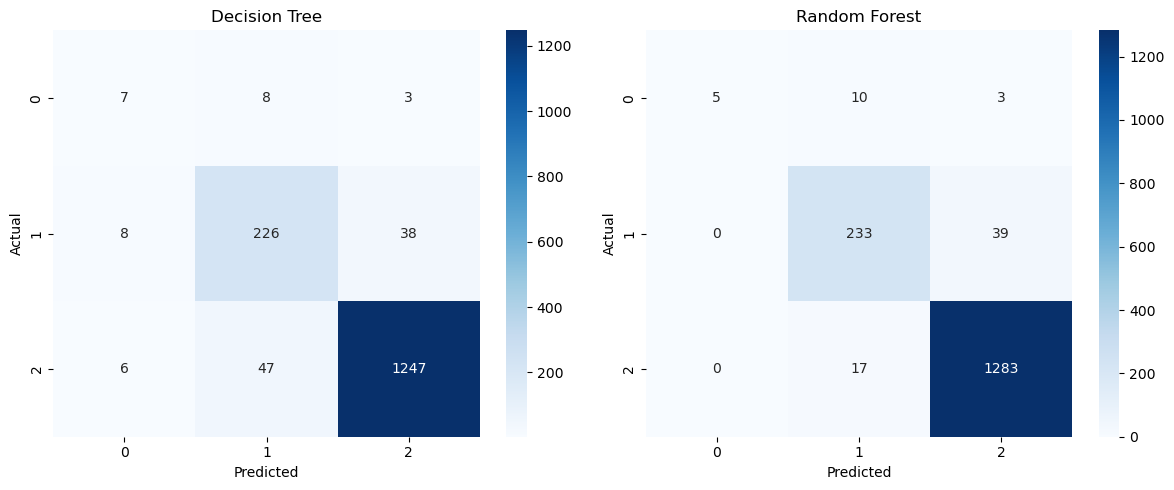

In [57]:
from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Decision Tree
cm_dt = confusion_matrix(y_test, yhat_dt)
sns.heatmap(cm_dt, annot=True, fmt='d', cmap='Blues', ax=axes[0])
axes[0].set_title("Decision Tree")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

# Random Forest
cm_rf = confusion_matrix(y_test, yhat)
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Blues', ax=axes[1])
axes[1].set_title("Random Forest")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

plt.tight_layout()
plt.show()

Decision Tree model showed an evident enhancement as compared to the baseline. It had the accuracy of 0.904, the precision of 0.615, the recall of 0.690, and the F-score of 0.636. This model managed to interact with certain underlying patterns of the data but its performance suggests that it was moderate especially with regard to differentiating the level of severity. The confusion analysis indicates that the Decision Tree was not good at separating closely related classes, particularly between level 2 and level 3 of severity, indicating that the model does not generalise and is susceptible to the presence of the imbalance between classes.

Random Forest model gave the best performance of all models. It has obtained a precision of 0.889, recall of 0.706, accuracy of 0.951 and F-score of 0.751 which is much higher than the Decision Tree. The increased accuracy and F-score suggests that the model makes more balanced predictions and not only on the majority classes but also on the minority categories. The confusion matrix also confirms this that there is less misclassification, and the majority class is more identified, and at the same time it is performing better on lower-frequency classes.

In comparison, the Random Forest model has the advantage of the ensemble character, which minimises variance and enhances generalisation than a single Decision Tree. Although both models are a little bit sensitive to the skewness in the classes, the introduction of the class weighting and feature selection has improved the capability of the models to deal with skewed data. In general, Random Forest model has better predictive accuracy and strength hence it is the most appropriate model to be used in this study to predict the scale of accidents.

## **6. Conclusion**

In this study, the models were created to predict the severity of accidents using structured preprocessing and machine learning algorithms. Although the Decision Tree algorithm performed better than the baseline, it only showed moderate performance and misclassification in the severity of accidents. The Random Forest algorithm gave the best results, as it showed high accuracy (0.951) and F1-score (0.751). The main factors affecting the severity of accidents include the speed limit, engine capacity, and age of the driver. The Random Forest algorithm is the most appropriate algorithm for solving the problem.

## **7. Recommendation**

* **Enforce speed regulations:** Improve monitoring of vehicles in areas where speed is a major factor to decrease the number of severe accidents.
* **Identify high-risk drivers:** Create awareness programs targeting drivers in certain age groups.
* **Promote safe vehicles:** Encourage drivers to use vehicles with certain safety features, especially those with higher engine capacity.
* **Collect more accurate data:** Include additional parameters such as traffic density, weather intensity, and time of day.
* **Improve model performance:** Investigate using alternative models such as Gradient Boosting or XG Boost.
* **Deal with class imbalance:** Consider using techniques such as SMOTE to improve the prediction of the minority class.
* **Deploy the model:** Use the model to make decisions and update it with new data.

## **References**



*   Pekar, V. (2024). Machine Learning for Business Analytics. Lecture examples and exercises. (Version 1.0.0). URL: https://github.com/vpekar/bd4dm




In [58]:
import json

# Replace with your notebook filename
notebook_file = "250206546_ML_Assignment.ipynb"

with open(notebook_file, "r", encoding="utf-8") as f:
    nb = json.load(f)

word_count = 0

for cell in nb["cells"]:
    if cell["cell_type"] in ["markdown"]:
        text = "".join(cell.get("source", []))
        word_count += len(text.split())
print("Total word count for notebook:", word_count)


Total word count for notebook: 3624
